# 🚗 Team 53 — Machine Learning Based Lifecycle Intelligence System
### Automotive Material Lifecycle Prediction Pipeline

---

**Project Overview:**  
This notebook implements a full ML pipeline to predict the lifecycle disposition of automotive materials (Recycle / Reuse / Dispose).

**Phases covered:**
1. 📦 Dataset Loading & Audit
2. 🧹 Preprocessing & Cleaning
3. 🔢 Feature Encoding
4. ✂️ Train / Validation / Test Split (70% / 10% / 20%)
5. 🤖 Model Training — RF, XGBoost, SVM, Hybrid Stacking
6. 📊 Hyperparameter Tuning (GridSearchCV)
7. 📈 Epoch / Boosting-round tracking (XGBoost)
8. 🏆 Model Comparison & Final Test Evaluation
9. 💾 Results Export to ../results/

> **Evaluator feedback addressed:** remove missing rows · 70/20/10 split · multiple algorithms including hybrid · learning rate + epoch tracking · validation loss & accuracy plotted · GridSearchCV tuning

---
## 📚 Cell 0 — Imports & Global Settings

In [1]:
import os
import json
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, log_loss, ConfusionMatrixDisplay
)
from xgboost import XGBClassifier

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.rcParams.update({'figure.dpi': 120, 'axes.grid': True, 'grid.alpha': 0.3, 'font.size': 11})
sns.set_style('whitegrid')

# All outputs go to the results folder
NOTEBOOK_DIR = os.path.dirname(os.path.abspath('__file__'))
RESULTS_DIR = os.path.join('..', 'results')
os.makedirs(RESULTS_DIR, exist_ok=True)

print('✅ All imports successful')
print(f'NumPy: {np.__version__} | Pandas: {pd.__version__}')

✅ All imports successful
NumPy: 2.0.2 | Pandas: 2.3.3


---
## 📦 Cell 1 — Load Dataset

In [2]:
DATA_PATH = os.path.join('..', 'data', 'automotive_material_lifecycle_v2.csv')

df_raw = pd.read_csv(DATA_PATH)

# v2 schema has two targets: Disposition (primary) and Environmental Risk.
# Environmental Risk is excluded from the features so it cannot leak into the Disposition model.
TARGET_COL = 'Disposition'
OTHER_TARGETS = ['Environmental Risk']

print(f'📊 Raw dataset shape: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns')
df_raw.head(5)

📊 Raw dataset shape: 9,000 rows × 30 columns


,Material Name,Material Family,Component,Vehicle Type,Joining Method,Manufacturing Year,Service Life (years),Odometer (km),Part Mass (kg),Density (kg/m3),...,Fluid Contamination,Coating Present,Hazardous Level,Legacy Additive (pre-ELV),Safety Critical,Reprocessable,Recyclate Value ($),Dismantling Cost ($),Disposition,Environmental Risk
0,Structural Steel,Ferrous metal,Bumper,Hybrid,Bolted,2008,17.60,142225.0,14.192,7850.0,...,No,No,Low,No,No,Yes,3.56,7.51,Recycle,Low
1,Aluminum Alloy (6061),Non-ferrous metal,Engine Mount,Electric,Bolted,2014,11.60,197679.0,4.378,2700.0,...,Yes,No,Low,No,Yes,Yes,4.92,19.23,Recycle,Moderate
2,Natural Rubber (vulcanised),Elastomer,Tyre,Electric,Clip-fit,2012,13.69,256039.0,6.894,1150.0,...,No,No,High,No,Yes,No,0.84,5.01,Dispose,High
3,Polyurethane (PU),Thermoset,Dashboard,ICE,Bolted,2017,9.13,134303.0,16.297,1200.0,...,No,No,High,No,No,No,2.10,19.22,Dispose,Critical
4,Natural Rubber (vulcanised),Elastomer,Tyre,Electric,Over-moulded,2018,7.60,131171.0,7.784,1150.0,...,No,No,High,No,Yes,No,1.00,14.70,Dispose,High


---
## 🔍 Cell 2 — Dataset Audit

In [3]:
# 2a. Schema & dtypes
print('=' * 60)
print('COLUMN INFO')
print('=' * 60)
df_raw.info()

COLUMN INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9000 entries, 0 to 8999
Data columns (total 30 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Material Name                    9000 non-null   object 
 1   Material Family                  9000 non-null   object 
 2   Component                        9000 non-null   object 
 3   Vehicle Type                     9000 non-null   object 
 4   Joining Method                   9000 non-null   object 
 5   Manufacturing Year               9000 non-null   int64  
 6   Service Life (years)             9000 non-null   float64
 7   Odometer (km)                    8921 non-null   float64
 8   Part Mass (kg)                   9000 non-null   float64
 9   Density (kg/m3)                  9000 non-null   float64
 10  Virgin Tensile Strength (MPa)    9000 non-null   float64
 11  Measured Tensile Strength (MPa)  8902 non-null   float64
 12  Max Serv

In [4]:
# 2b. Missing values
missing = df_raw.isnull().sum()
missing_pct = (missing / len(df_raw) * 100).round(2)
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
missing_df = missing_df[missing_df['Missing Count'] > 0].sort_values('Missing Count', ascending=False)

print(f'Total rows with at least one NaN: {df_raw.isnull().any(axis=1).sum()}')
print(f'Columns with NaN:')
display(missing_df)

Total rows with at least one NaN: 560
Columns with NaN:


,Missing Count,Missing %
Recycling Efficiency (%),109,1.21
Surface Degradation Grade,100,1.11
Measured Tensile Strength (MPa),98,1.09
Recyclate Value ($),95,1.06
Recycled Content (%),90,1.00
Odometer (km),79,0.88


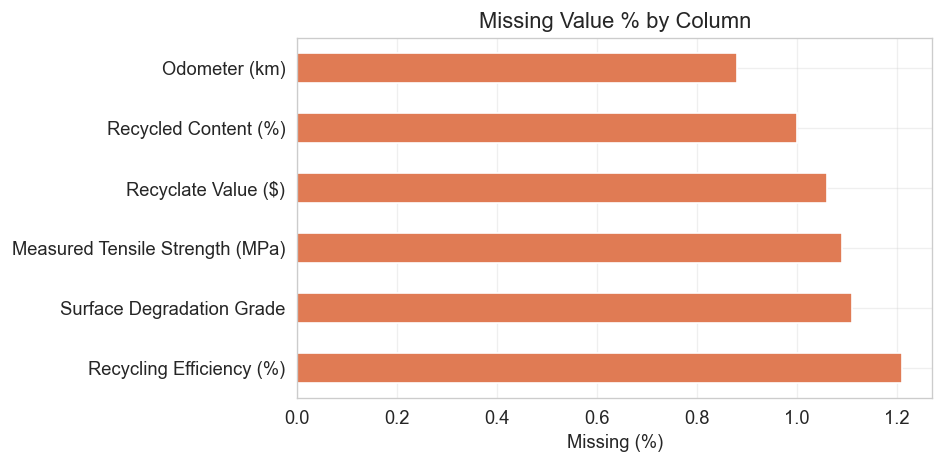

In [5]:
# 2c. Visualise missing values
if len(missing_df) > 0:
    fig, ax = plt.subplots(figsize=(8, 4))
    missing_df['Missing %'].plot(kind='barh', ax=ax, color='#E07B54')
    ax.set_xlabel('Missing (%)')
    ax.set_title('Missing Value % by Column')
    plt.tight_layout()
    plt.show()
else:
    print('✅ No missing values found!')

In [6]:
# 2d. Descriptive statistics (numeric)
print('Descriptive Statistics (Numeric Features):')
df_raw.describe().round(3)

Descriptive Statistics (Numeric Features):


,Manufacturing Year,Service Life (years),Odometer (km),Part Mass (kg),Density (kg/m3),Virgin Tensile Strength (MPa),Measured Tensile Strength (MPa),Max Service Temp (C),Embodied Energy (MJ),Carbon Footprint (kg CO2eq),CO2 Avoided if Recycled (kg),Recycling Efficiency (%),Recycled Content (%),Surface Degradation Grade,Recyclate Value ($),Dismantling Cost ($)
count,9000.000,9000.000,8921.000,9000.000,9000.000,9000.000,8902.000,9000.000,9000.000,9000.000,9000.000,8891.000,8910.000,8900.000,8905.000,9000.000
mean,2012.027,13.976,221045.642,15.906,3089.308,194.658,163.041,226.963,1390.765,86.971,56.901,27.774,20.151,1.756,9.717,18.588
std,5.251,5.243,114821.774,10.918,2771.138,184.589,158.314,165.845,1771.361,134.709,82.962,21.415,18.159,0.942,20.389,6.309
min,1994.000,2.340,24378.000,1.446,905.000,16.660,5.420,70.000,60.590,3.904,2.118,1.150,0.450,1.000,0.130,2.800
25%,2009.000,10.100,137083.000,8.251,1150.000,33.220,25.430,95.000,435.360,19.235,13.697,9.575,5.730,1.000,1.570,14.520
50%,2013.000,13.320,197289.000,13.439,1550.000,53.195,49.825,150.000,830.970,37.893,27.579,19.370,14.060,1.000,3.850,18.700
75%,2016.000,17.092,278873.000,20.757,2700.000,376.300,296.565,400.000,1372.232,84.317,52.656,47.245,29.892,2.000,7.420,22.690
max,2024.000,32.000,600000.000,90.842,8940.000,709.140,702.350,500.000,15197.220,1275.291,677.346,99.000,67.490,5.000,250.210,51.940


In [7]:
# 2e. Categorical feature distributions
cat_cols = df_raw.select_dtypes(include='object').columns.tolist()
print(f'Categorical columns: {cat_cols}\n')
for col in cat_cols:
    print(f'--- {col} ---')
    print(df_raw[col].value_counts().to_string())
    print()

Categorical columns: ['Material Name', 'Material Family', 'Component', 'Vehicle Type', 'Joining Method', 'Material Condition', 'Fluid Contamination', 'Coating Present', 'Hazardous Level', 'Legacy Additive (pre-ELV)', 'Safety Critical', 'Reprocessable', 'Disposition', 'Environmental Risk']

--- Material Name ---
Material Name
Structural Steel                          1904
Polypropylene (PP)                        1387
Aluminum Alloy (6061)                     1128
Automotive Glass (laminated)               744
Natural Rubber (vulcanised)                638
Polyvinyl Chloride (PVC)                   621
Polyurethane (PU)                          610
Acrylonitrile Butadiene Styrene (ABS)      568
Glass Fiber Reinforced Polymer (GFRP)      507
Carbon Fiber Reinforced Polymer (CFRP)     417
Polyethylene (HDPE)                        263
Copper Alloy                               213

--- Material Family ---
Material Family
Thermoplastic        2839
Ferrous metal        1904
Non-ferrous meta

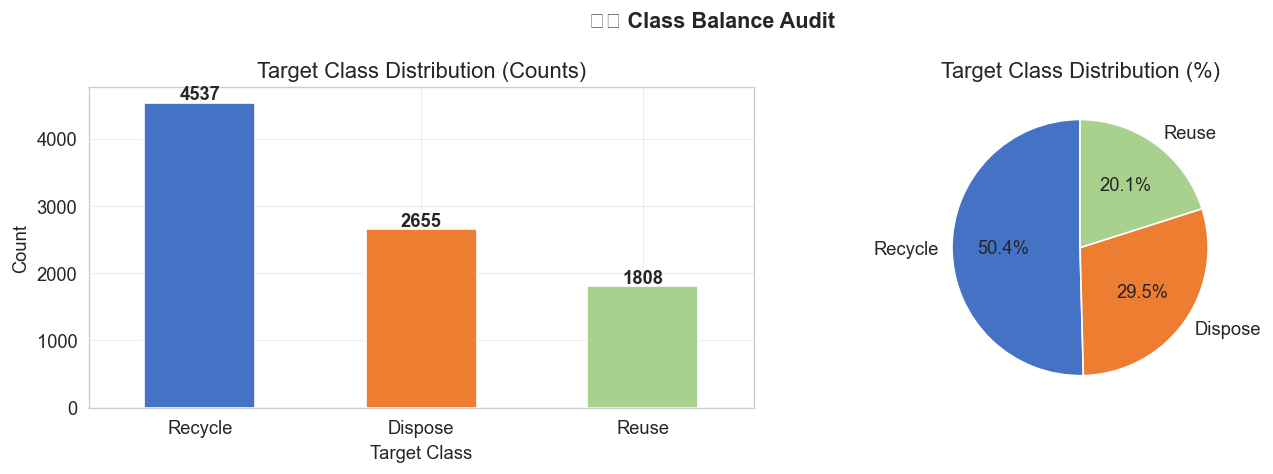

Disposition
Recycle    4537
Dispose    2655
Reuse      1808
Name: count, dtype: int64

Class imbalance ratio (max/min): 2.51x


In [8]:
# 2f. Target class distribution
target_counts = df_raw[TARGET_COL].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
colors = ['#4472C4', '#ED7D31', '#A9D18E']
target_counts.plot(kind='bar', ax=axes[0], color=colors, edgecolor='white')
axes[0].set_title('Target Class Distribution (Counts)')
axes[0].set_xlabel('Target Class')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=0)
for i, v in enumerate(target_counts.values):
    axes[0].text(i, v + target_counts.max()*0.01, str(v), ha='center', fontweight='bold')

target_counts.plot(kind='pie', ax=axes[1], colors=colors, autopct='%1.1f%%', startangle=90)
axes[1].set_ylabel('')
axes[1].set_title('Target Class Distribution (%)')

plt.suptitle('⚖️ Class Balance Audit', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print(target_counts)
print(f'\nClass imbalance ratio (max/min): {target_counts.max()/target_counts.min():.2f}x')

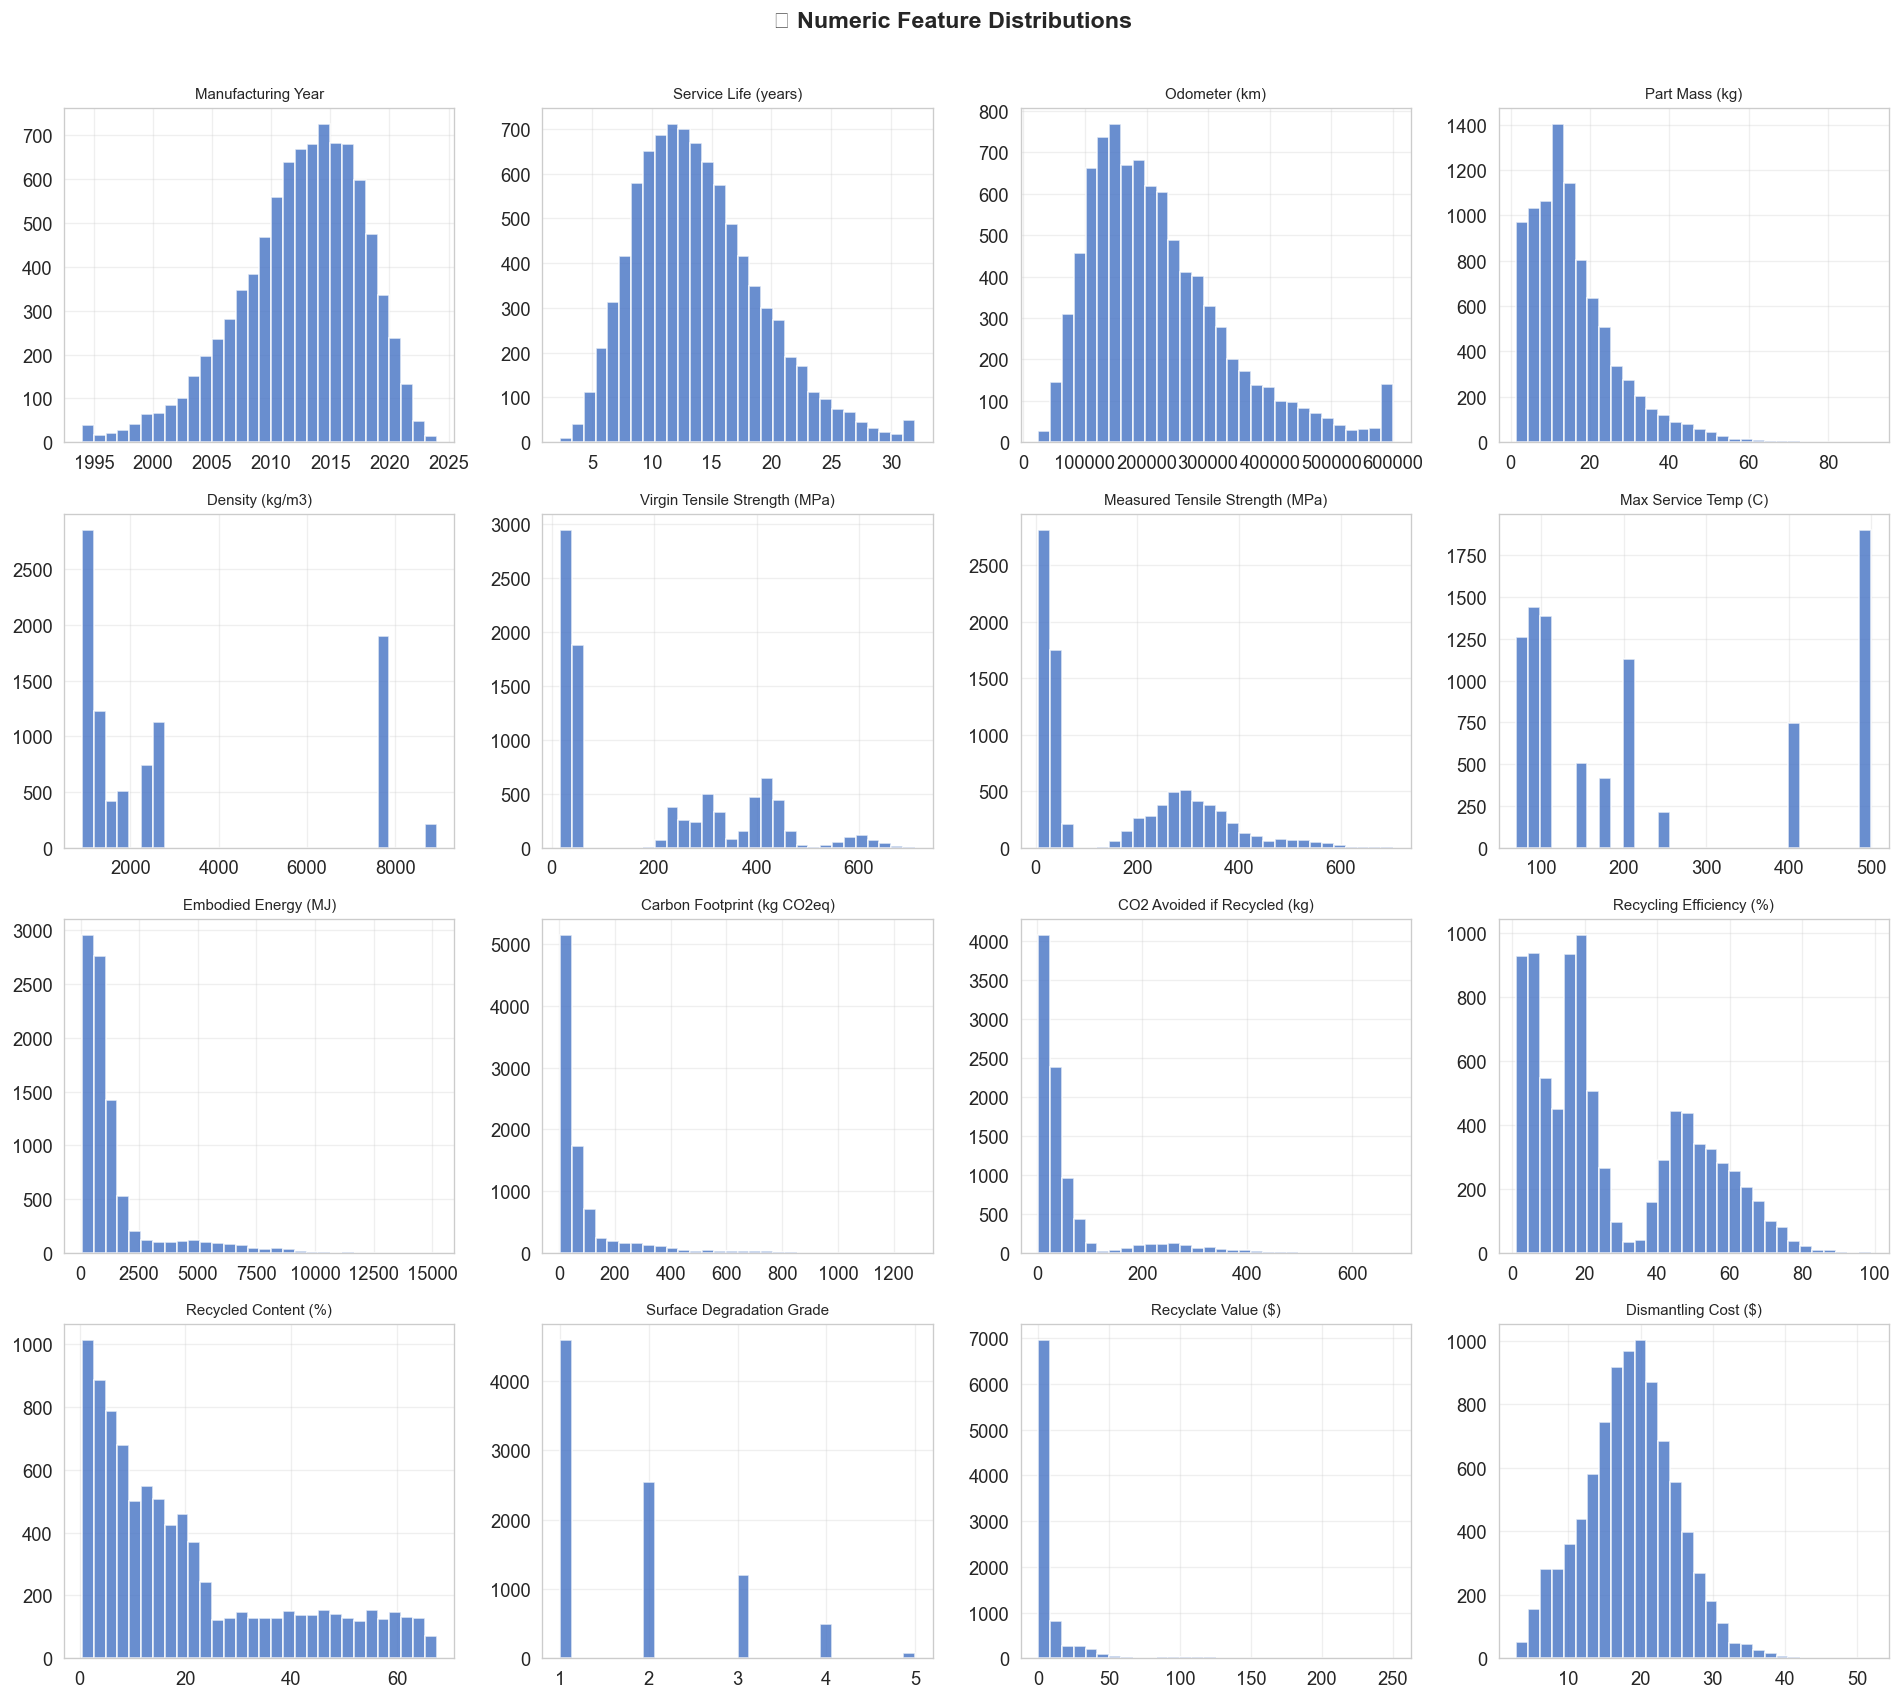

In [9]:
# 2g. Numeric feature histograms
num_cols = df_raw.select_dtypes(include=np.number).columns.tolist()
n = len(num_cols)
ncols = 4
nrows = (n + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(16, nrows * 3.5))
axes_flat = axes.flatten()

for i, col in enumerate(num_cols):
    axes_flat[i].hist(df_raw[col].dropna(), bins=30, color='#4472C4', edgecolor='white', alpha=0.8)
    axes_flat[i].set_title(col, fontsize=9)

for j in range(i+1, len(axes_flat)):
    axes_flat[j].set_visible(False)

plt.suptitle('📊 Numeric Feature Distributions', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

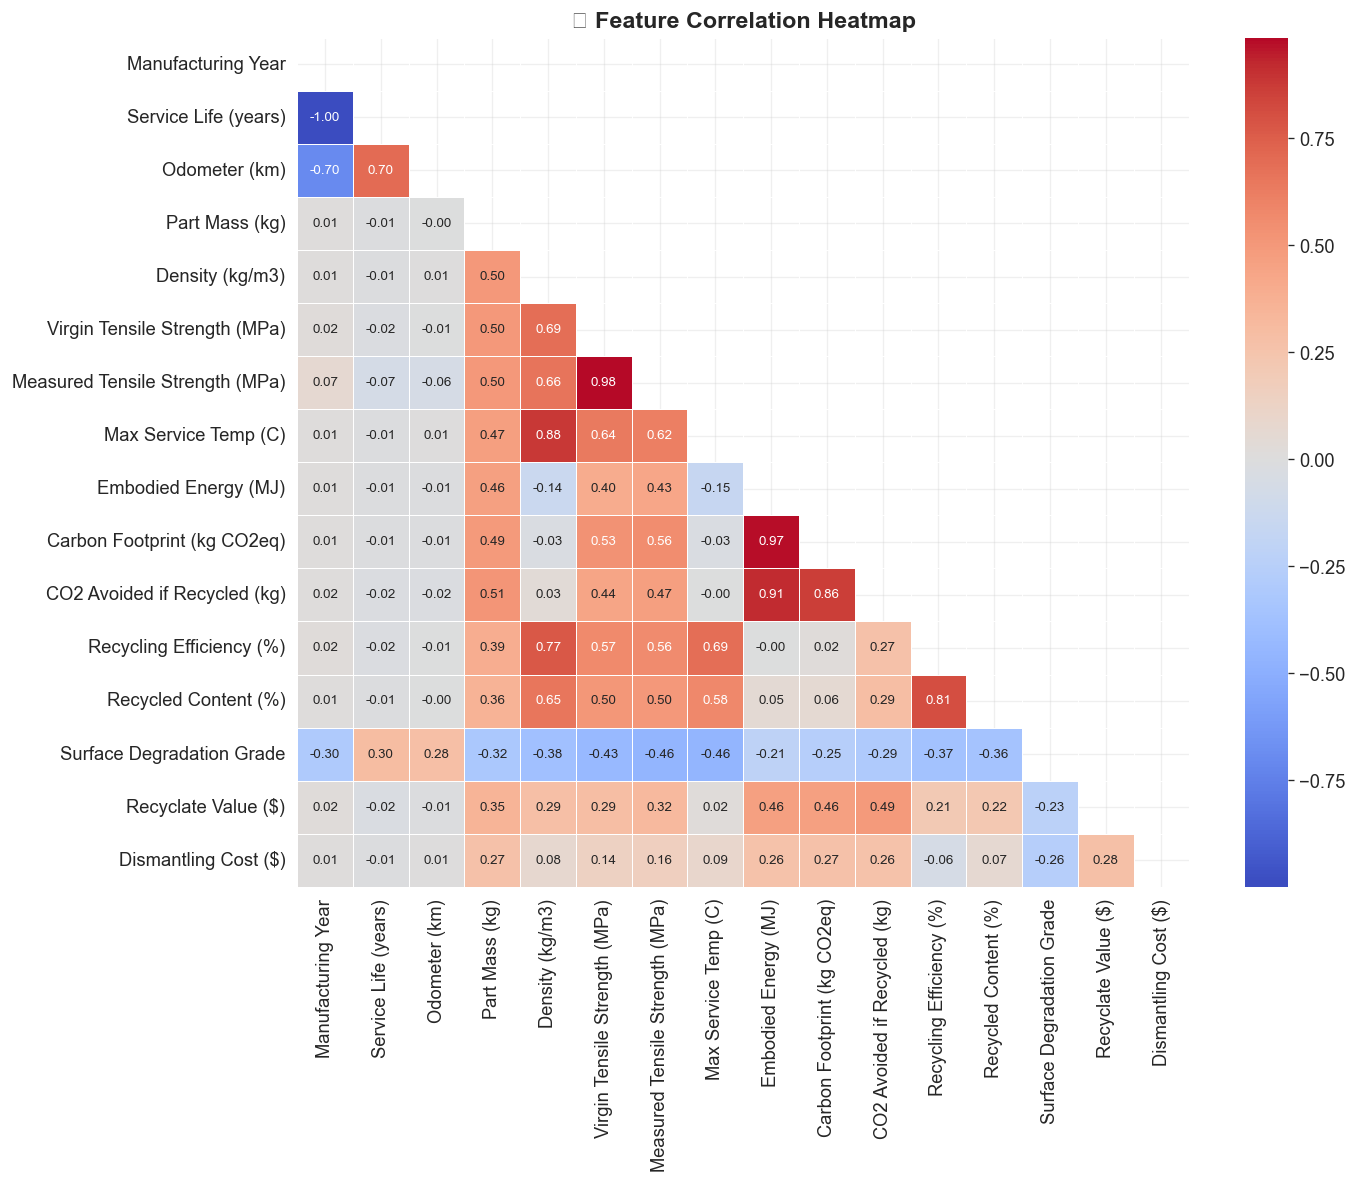

In [10]:
# 2h. Correlation heatmap
corr = df_raw[num_cols].corr()
fig, ax = plt.subplots(figsize=(12, 10))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, linewidths=0.5, ax=ax, annot_kws={'size': 8})
ax.set_title('🔗 Feature Correlation Heatmap', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [11]:
# 2i. Duplicates & Outliers (IQR)
dups = df_raw.duplicated().sum()
print(f'Duplicate rows: {dups}')

print('\nOutlier counts per numeric column (IQR method):')
outlier_counts = {}
for col in num_cols:
    Q1 = df_raw[col].quantile(0.25)
    Q3 = df_raw[col].quantile(0.75)
    IQR = Q3 - Q1
    n_out = ((df_raw[col] < Q1 - 1.5*IQR) | (df_raw[col] > Q3 + 1.5*IQR)).sum()
    outlier_counts[col] = n_out

out_s = pd.Series(outlier_counts).sort_values(ascending=False)
print(out_s[out_s > 0].to_string())

Duplicate rows: 0

Outlier counts per numeric column (IQR method):
Density (kg/m3)                 2117
Recyclate Value ($)             1157
Carbon Footprint (kg CO2eq)     1129
Embodied Energy (MJ)            1064
CO2 Avoided if Recycled (kg)    1028
Surface Degradation Grade        568
Part Mass (kg)                   388
Odometer (km)                    317
Manufacturing Year               146
Service Life (years)             142
Dismantling Cost ($)              72
Recycled Content (%)              35


---
## 🧹 Cell 3 — Preprocessing & Cleaning

In [12]:
# Drop rows with any NaN (evaluator feedback: remove missing rows)
df = df_raw.dropna().reset_index(drop=True)

rows_dropped = len(df_raw) - len(df)
print(f'Rows before : {len(df_raw):,}')
print(f'Rows dropped: {rows_dropped:,}  ({rows_dropped/len(df_raw)*100:.1f}%)')
print(f'Rows after  : {len(df):,}')

assert df.isnull().sum().sum() == 0, '❌ NaN still present!'
print('\n✅ Zero missing values after cleaning')

Rows before : 9,000
Rows dropped: 560  (6.2%)
Rows after  : 8,440

✅ Zero missing values after cleaning


---
## 🔢 Cell 4 — Feature Encoding

In [13]:
categorical_cols = [
    c for c in df.select_dtypes(include='object').columns
    if c != TARGET_COL and c not in OTHER_TARGETS
]
target_col = TARGET_COL

encoders = {}
df_enc = df.drop(columns=OTHER_TARGETS).copy()

for col in categorical_cols:
    le = LabelEncoder()
    df_enc[col] = le.fit_transform(df_enc[col])
    encoders[col] = dict(zip(le.classes_, le.transform(le.classes_).tolist()))
    print(f'{col}: {encoders[col]}')

target_encoder = LabelEncoder()
y_all = target_encoder.fit_transform(df_enc[target_col])
class_names = list(target_encoder.classes_)
print(f'\nTarget classes → {dict(zip(class_names, range(len(class_names))))}')

feature_cols = [c for c in df_enc.columns if c != target_col]
X_all = df_enc[feature_cols].values
print(f'\nFeature matrix: {X_all.shape}  |  Target vector: {y_all.shape}')


Material Name: {'Acrylonitrile Butadiene Styrene (ABS)': 0, 'Aluminum Alloy (6061)': 1, 'Automotive Glass (laminated)': 2, 'Carbon Fiber Reinforced Polymer (CFRP)': 3, 'Copper Alloy': 4, 'Glass Fiber Reinforced Polymer (GFRP)': 5, 'Natural Rubber (vulcanised)': 6, 'Polyethylene (HDPE)': 7, 'Polypropylene (PP)': 8, 'Polyurethane (PU)': 9, 'Polyvinyl Chloride (PVC)': 10, 'Structural Steel': 11}
Material Family: {'Ceramic / glass': 0, 'Composite': 1, 'Elastomer': 2, 'Ferrous metal': 3, 'Non-ferrous metal': 4, 'Thermoplastic': 5, 'Thermoset': 6}
Component: {'Battery Casing': 0, 'Body Panel': 1, 'Bumper': 2, 'Chassis Member': 3, 'Dashboard': 4, 'Engine Mount': 5, 'Fuel Tank': 6, 'Interior Trim': 7, 'Seat Assembly': 8, 'Tyre': 9, 'Windscreen': 10, 'Wiring Harness': 11}
Vehicle Type: {'Electric': 0, 'Hybrid': 1, 'ICE': 2}
Joining Method: {'Adhesive-bonded': 0, 'Bolted': 1, 'Clip-fit': 2, 'Over-moulded': 3, 'Welded': 4}
Material Condition: {'Excellent': 0, 'Fair': 1, 'Good': 2, 'Poor': 3}
Flui

---
## ✂️ Cell 5 — Dataset Split (70% Train / 20% Test / 10% Validation)

In [14]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X_all, y_all, test_size=0.30, random_state=RANDOM_STATE, stratify=y_all
)
X_test, X_val, y_test, y_val = train_test_split(
    X_temp, y_temp, test_size=(10/30), random_state=RANDOM_STATE, stratify=y_temp
)

total = len(X_all)
print('Split summary:')
print(f'  Train:      {len(X_train):4d}  ({len(X_train)/total:.1%})')
print(f'  Test:       {len(X_test):4d}  ({len(X_test)/total:.1%})')
print(f'  Validation: {len(X_val):4d}  ({len(X_val)/total:.1%})')
print(f'  Total:      {total:4d}')

print('\nClass distribution per split:')
for name, y in [('Train', y_train), ('Test', y_test), ('Validation', y_val)]:
    counts = np.bincount(y)
    pcts = counts / len(y) * 100
    row = '  |  '.join([f'{class_names[i]}: {counts[i]} ({pcts[i]:.1f}%)' for i in range(len(class_names))])
    print(f'  {name:12s}: {row}')
print('\n✅ Stratified split complete')

Split summary:
  Train:      5908  (70.0%)
  Test:       1688  (20.0%)
  Validation:  844  (10.0%)
  Total:      8440

Class distribution per split:
  Train       : Dispose: 1736 (29.4%)  |  Recycle: 2995 (50.7%)  |  Reuse: 1177 (19.9%)
  Test        : Dispose: 496 (29.4%)  |  Recycle: 855 (50.7%)  |  Reuse: 337 (20.0%)
  Validation  : Dispose: 248 (29.4%)  |  Recycle: 428 (50.7%)  |  Reuse: 168 (19.9%)

✅ Stratified split complete


---
## 🤖 Cell 6A — Model 1: Random Forest (with GridSearchCV)

In [15]:
print('Training Random Forest with GridSearchCV...')
rf_param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [8, 12, None],
    'min_samples_split': [2, 5],
}
rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE),
    rf_param_grid, cv=3, scoring='accuracy', n_jobs=-1, verbose=0
)
rf_grid.fit(X_train, y_train)
best_rf = rf_grid.best_estimator_

print(f'Best RF params: {rf_grid.best_params_}')
print(f'CV best score:  {rf_grid.best_score_:.4f}')

val_pred_rf  = best_rf.predict(X_val)
val_proba_rf = best_rf.predict_proba(X_val)
rf_metrics = {
    'best_params':   rf_grid.best_params_,
    'val_accuracy':  accuracy_score(y_val, val_pred_rf),
    'val_loss':      log_loss(y_val, val_proba_rf),
    'val_precision': precision_score(y_val, val_pred_rf, average='macro'),
    'val_recall':    recall_score(y_val, val_pred_rf, average='macro'),
    'val_f1':        f1_score(y_val, val_pred_rf, average='macro'),
}
print(f'Val accuracy: {rf_metrics["val_accuracy"]:.4f}  |  Val loss: {rf_metrics["val_loss"]:.4f}  |  Val F1: {rf_metrics["val_f1"]:.4f}')

Training Random Forest with GridSearchCV...


Best RF params: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 100}
CV best score:  0.8803
Val accuracy: 0.8732  |  Val loss: 0.3953  |  Val F1: 0.8420


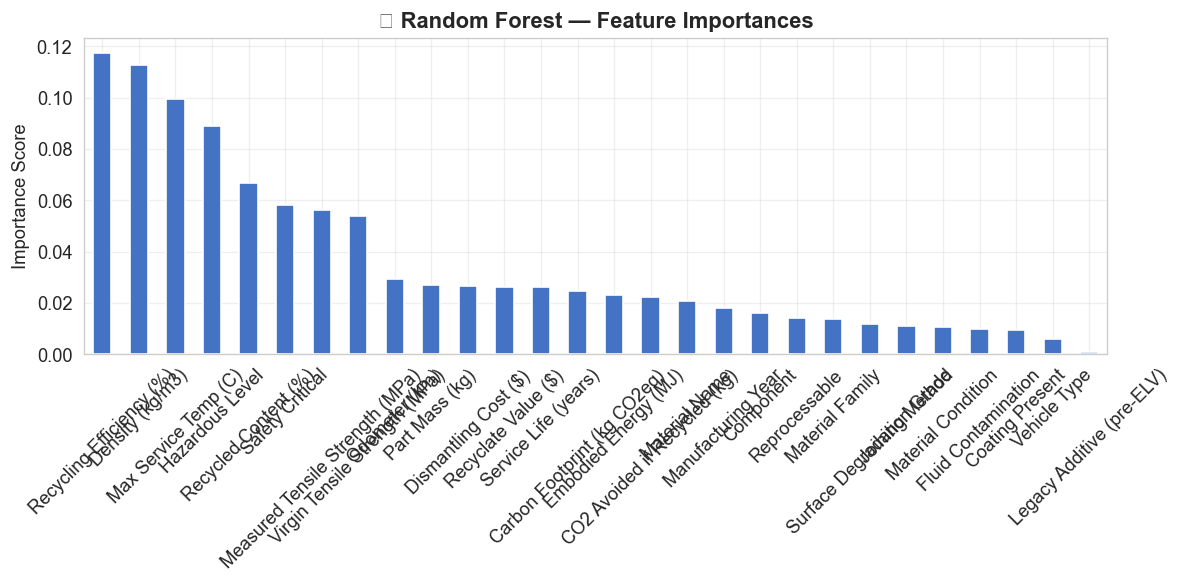

✅ Saved rf_feature_importance.png


In [16]:
# Feature importances
feat_imp = pd.Series(best_rf.feature_importances_, index=feature_cols).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 5))
feat_imp.plot(kind='bar', ax=ax, color='#4472C4', edgecolor='white')
ax.set_title('🌲 Random Forest — Feature Importances', fontweight='bold')
ax.set_ylabel('Importance Score')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'rf_feature_importance.png'), dpi=150)
plt.show()
print('✅ Saved rf_feature_importance.png')

---
## 📈 Cell 6A-2 — Random Forest "Epoch" Curve (30 rounds, via `warm_start`)

Random Forest builds trees independently (bagging), so it has no native per-epoch loss like XGBoost's boosting rounds. 
To get a comparable training curve, we use `warm_start=True` and add one tree at a time (1 → 30 trees), 
recording train/validation accuracy and log-loss after each addition — same best hyperparameters as the tuned model above.

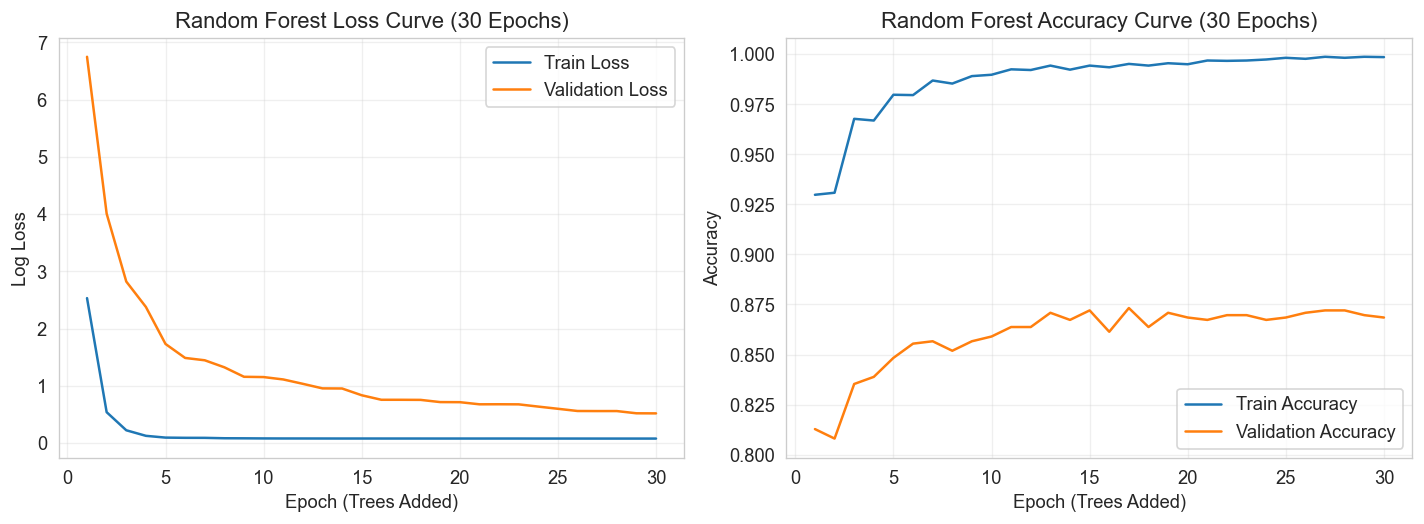

Final (epoch 30) — Train acc: 0.9985  |  Val acc: 0.8685
Final (epoch 30) — Train loss: 0.0785  |  Val loss: 0.5186
✅ Saved rf_training_curves.png


In [17]:
N_EPOCHS = 30

rf_epoch = RandomForestClassifier(
    n_estimators=1,
    max_depth=rf_grid.best_params_['max_depth'],
    min_samples_split=rf_grid.best_params_['min_samples_split'],
    random_state=RANDOM_STATE,
    warm_start=True,
)

train_acc_curve, val_acc_curve = [], []
train_loss_curve, val_loss_curve = [], []

for epoch in range(1, N_EPOCHS + 1):
    rf_epoch.n_estimators = epoch
    rf_epoch.fit(X_train, y_train)

    train_proba = rf_epoch.predict_proba(X_train)
    val_proba   = rf_epoch.predict_proba(X_val)

    train_acc_curve.append(accuracy_score(y_train, rf_epoch.predict(X_train)))
    val_acc_curve.append(accuracy_score(y_val, rf_epoch.predict(X_val)))
    train_loss_curve.append(log_loss(y_train, train_proba, labels=np.unique(y_all)))
    val_loss_curve.append(log_loss(y_val, val_proba, labels=np.unique(y_all)))

epochs_range = range(1, N_EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(epochs_range, train_loss_curve, label='Train Loss')
axes[0].plot(epochs_range, val_loss_curve, label='Validation Loss')
axes[0].set_xlabel('Epoch (Trees Added)')
axes[0].set_ylabel('Log Loss')
axes[0].set_title('Random Forest Loss Curve (30 Epochs)')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs_range, train_acc_curve, label='Train Accuracy')
axes[1].plot(epochs_range, val_acc_curve, label='Validation Accuracy')
axes[1].set_xlabel('Epoch (Trees Added)')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Random Forest Accuracy Curve (30 Epochs)')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'rf_training_curves.png'), dpi=150)
plt.show()

print(f'Final (epoch {N_EPOCHS}) — Train acc: {train_acc_curve[-1]:.4f}  |  Val acc: {val_acc_curve[-1]:.4f}')
print(f'Final (epoch {N_EPOCHS}) — Train loss: {train_loss_curve[-1]:.4f}  |  Val loss: {val_loss_curve[-1]:.4f}')
print('✅ Saved rf_training_curves.png')


---
## 🤖 Cell 6B — Model 2: XGBoost (Epoch / LR / Val-loss tracking)

In [18]:
print('Training XGBoost with GridSearchCV...')
xgb_param_grid = {
    'n_estimators': [150],
    'learning_rate': [0.05, 0.1, 0.2],
    'max_depth': [4, 6],
}
xgb_grid = GridSearchCV(
    XGBClassifier(objective='multi:softprob', eval_metric='mlogloss',
                  random_state=RANDOM_STATE),
    xgb_param_grid, cv=3, scoring='accuracy', n_jobs=-1, verbose=0
)
xgb_grid.fit(X_train, y_train)
best_params = xgb_grid.best_params_

print(f'Best XGBoost params: {best_params}')
print(f'CV best score:       {xgb_grid.best_score_:.4f}')

# Retrain with eval_set to capture per-round curves
best_xgb = XGBClassifier(
    n_estimators=best_params['n_estimators'],
    learning_rate=best_params['learning_rate'],
    max_depth=best_params['max_depth'],
    objective='multi:softprob',
    eval_metric=['mlogloss', 'merror'],
    random_state=RANDOM_STATE,
)
best_xgb.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_val, y_val)],
    verbose=False,
)
evals_result = best_xgb.evals_result()

val_pred_xgb  = best_xgb.predict(X_val)
val_proba_xgb = best_xgb.predict_proba(X_val)
xgb_metrics = {
    'best_params':   best_params,
    'val_accuracy':  accuracy_score(y_val, val_pred_xgb),
    'val_loss':      log_loss(y_val, val_proba_xgb),
    'val_precision': precision_score(y_val, val_pred_xgb, average='macro'),
    'val_recall':    recall_score(y_val, val_pred_xgb, average='macro'),
    'val_f1':        f1_score(y_val, val_pred_xgb, average='macro'),
}
print(f'Val accuracy: {xgb_metrics["val_accuracy"]:.4f}  |  Val loss: {xgb_metrics["val_loss"]:.4f}  |  Val F1: {xgb_metrics["val_f1"]:.4f}')

Training XGBoost with GridSearchCV...


Best XGBoost params: {'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 150}
CV best score:       0.8802


Val accuracy: 0.8791  |  Val loss: 0.3088  |  Val F1: 0.8512


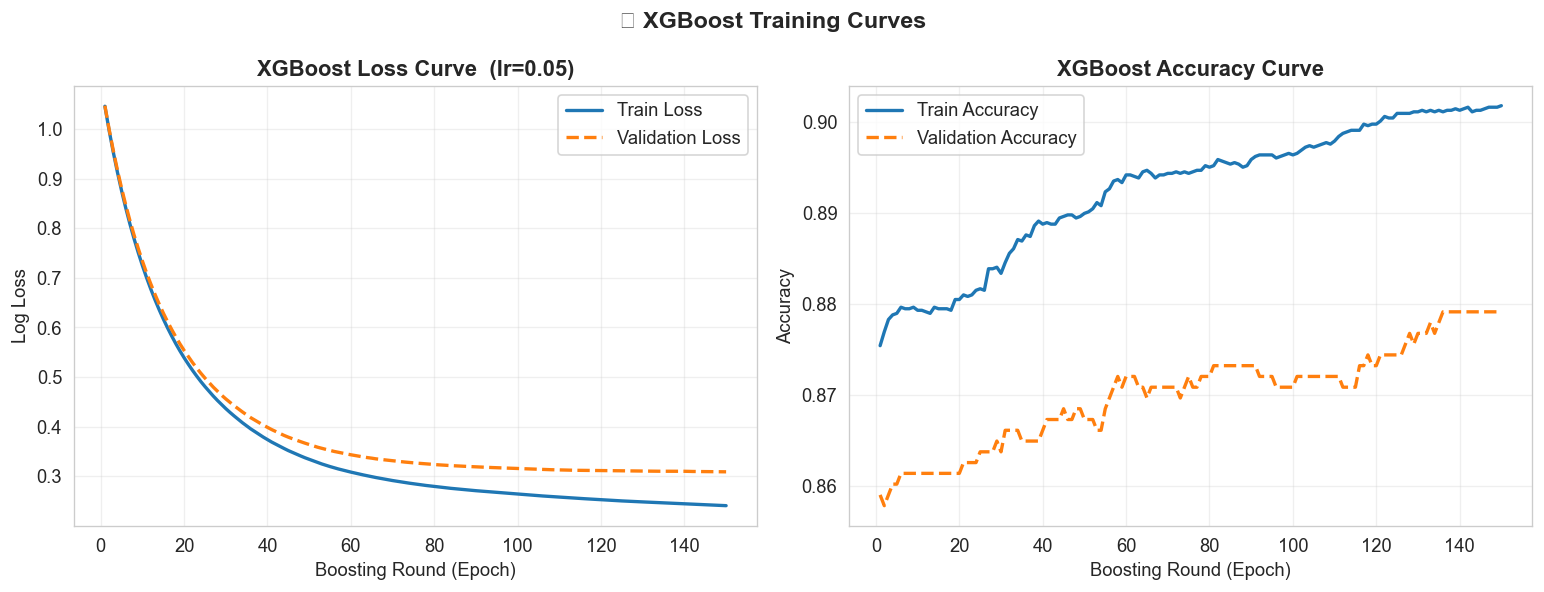

✅ Saved xgboost_training_curves.png


In [19]:
# Training curves plot
epochs = range(1, len(evals_result['validation_0']['mlogloss']) + 1)
train_acc_curve = [1 - e for e in evals_result['validation_0']['merror']]
val_acc_curve   = [1 - e for e in evals_result['validation_1']['merror']]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(epochs, evals_result['validation_0']['mlogloss'], label='Train Loss', lw=2)
axes[0].plot(epochs, evals_result['validation_1']['mlogloss'], label='Validation Loss', lw=2, ls='--')
axes[0].set_xlabel('Boosting Round (Epoch)')
axes[0].set_ylabel('Log Loss')
axes[0].set_title(f'XGBoost Loss Curve  (lr={best_params["learning_rate"]})', fontweight='bold')
axes[0].legend()

axes[1].plot(epochs, train_acc_curve, label='Train Accuracy', lw=2)
axes[1].plot(epochs, val_acc_curve,   label='Validation Accuracy', lw=2, ls='--')
axes[1].set_xlabel('Boosting Round (Epoch)')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('XGBoost Accuracy Curve', fontweight='bold')
axes[1].legend()

plt.suptitle('📈 XGBoost Training Curves', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'xgboost_training_curves.png'), dpi=150)
plt.show()
print('✅ Saved xgboost_training_curves.png')

---
## 🤖 Cell 6C — Model 3: SVM (Baseline)

In [20]:
print('Training SVM (RBF kernel)...')
# RBF kernels are distance-based, so features must be standardised (e.g. Odometer ~1e5 vs grades 1-5)
svm = make_pipeline(StandardScaler(), SVC(kernel='rbf', probability=True, random_state=RANDOM_STATE))
svm.fit(X_train, y_train)

val_pred_svm  = svm.predict(X_val)
val_proba_svm = svm.predict_proba(X_val)
svm_metrics = {
    'best_params':   {'kernel': 'rbf'},
    'val_accuracy':  accuracy_score(y_val, val_pred_svm),
    'val_loss':      log_loss(y_val, val_proba_svm),
    'val_precision': precision_score(y_val, val_pred_svm, average='macro'),
    'val_recall':    recall_score(y_val, val_pred_svm, average='macro'),
    'val_f1':        f1_score(y_val, val_pred_svm, average='macro'),
}
print(f'Val accuracy: {svm_metrics["val_accuracy"]:.4f}  |  Val loss: {svm_metrics["val_loss"]:.4f}  |  Val F1: {svm_metrics["val_f1"]:.4f}')

Training SVM (RBF kernel)...


Val accuracy: 0.8685  |  Val loss: 0.3665  |  Val F1: 0.8403


---
## 🤖 Cell 6D — Model 4: Hybrid Stacking Ensemble

In [21]:
print('Training Hybrid Stacking Ensemble (RF + XGBoost → LR meta-learner)...')
hybrid = StackingClassifier(
    estimators=[
        ('rf',  RandomForestClassifier(**rf_grid.best_params_, random_state=RANDOM_STATE)),
        ('xgb', XGBClassifier(**best_params, objective='multi:softprob',
                               eval_metric='mlogloss', random_state=RANDOM_STATE)),
    ],
    final_estimator=LogisticRegression(max_iter=1000),
    cv=3,
)
hybrid.fit(X_train, y_train)

val_pred_hybrid  = hybrid.predict(X_val)
val_proba_hybrid = hybrid.predict_proba(X_val)
hybrid_metrics = {
    'best_params':   'RF + XGBoost base learners, Logistic Regression meta-learner',
    'val_accuracy':  accuracy_score(y_val, val_pred_hybrid),
    'val_loss':      log_loss(y_val, val_proba_hybrid),
    'val_precision': precision_score(y_val, val_pred_hybrid, average='macro'),
    'val_recall':    recall_score(y_val, val_pred_hybrid, average='macro'),
    'val_f1':        f1_score(y_val, val_pred_hybrid, average='macro'),
}
print(f'Val accuracy: {hybrid_metrics["val_accuracy"]:.4f}  |  Val loss: {hybrid_metrics["val_loss"]:.4f}  |  Val F1: {hybrid_metrics["val_f1"]:.4f}')

Training Hybrid Stacking Ensemble (RF + XGBoost → LR meta-learner)...


Val accuracy: 0.8744  |  Val loss: 0.3331  |  Val F1: 0.8449


---
## 📊 Cell 7 — Model Comparison

In [22]:
results = {
    'Random Forest':                rf_metrics,
    'XGBoost':                      xgb_metrics,
    'SVM':                          svm_metrics,
    'Hybrid (RF + XGBoost Stacked)': hybrid_metrics,
}

comp_df = pd.DataFrame(results).T[['val_accuracy', 'val_loss', 'val_precision', 'val_recall', 'val_f1']]
comp_df.columns = ['Val Accuracy', 'Val Loss', 'Val Precision', 'Val Recall', 'Val F1']

print('=' * 70)
print('VALIDATION SET RESULTS — MODEL COMPARISON')
print('=' * 70)
display(comp_df.round(4))

best_model_name = comp_df['Val Accuracy'].idxmax()
print(f'\n🏆 Best model: "{best_model_name}"')
print(f'   Val Accuracy = {comp_df.loc[best_model_name, "Val Accuracy"]:.4f}')

VALIDATION SET RESULTS — MODEL COMPARISON


,Val Accuracy,Val Loss,Val Precision,Val Recall,Val F1
Random Forest,0.873223,0.395326,0.842254,0.841779,0.842015
XGBoost,0.879147,0.308831,0.850443,0.85234,0.851245
SVM,0.868483,0.366547,0.835418,0.846461,0.840327
Hybrid (RF + XGBoost Stacked),0.874408,0.333074,0.844393,0.845683,0.844878



🏆 Best model: "XGBoost"
   Val Accuracy = 0.8791


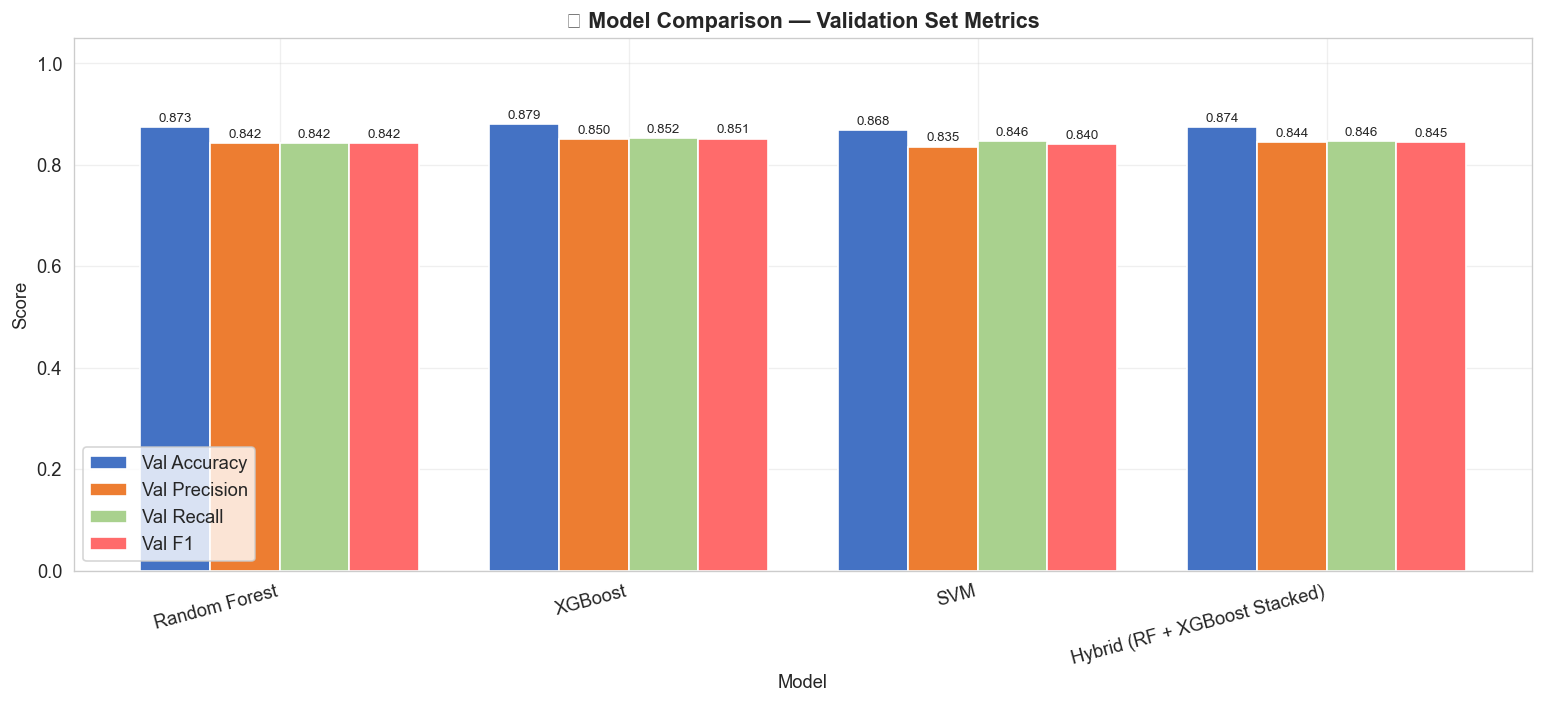

✅ Saved model_comparison.png


In [23]:
# Grouped bar chart
metrics_to_plot = ['Val Accuracy', 'Val Precision', 'Val Recall', 'Val F1']
x = np.arange(len(comp_df))
width = 0.2
palette = ['#4472C4', '#ED7D31', '#A9D18E', '#FF6B6B']

fig, ax = plt.subplots(figsize=(13, 6))
for i, metric in enumerate(metrics_to_plot):
    bars = ax.bar(x + i*width, comp_df[metric], width, label=metric, color=palette[i], edgecolor='white')
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., h + 0.005,
                f'{h:.3f}', ha='center', va='bottom', fontsize=8)

ax.set_xlabel('Model')
ax.set_ylabel('Score')
ax.set_title('🏆 Model Comparison — Validation Set Metrics', fontsize=13, fontweight='bold')
ax.set_xticks(x + width*1.5)
ax.set_xticklabels(comp_df.index, rotation=15, ha='right')
ax.set_ylim(0, 1.05)
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'model_comparison.png'), dpi=150)
plt.show()
print('✅ Saved model_comparison.png')

---
## 🎯 Cell 8 — Final Test-Set Evaluation of Best Model

In [24]:
model_lookup = {
    'Random Forest':                best_rf,
    'XGBoost':                      best_xgb,
    'SVM':                          svm,
    'Hybrid (RF + XGBoost Stacked)': hybrid,
}

final_model = model_lookup[best_model_name]
test_pred   = final_model.predict(X_test)
test_acc    = accuracy_score(y_test, test_pred)

print(f'🏆 Best model: {best_model_name}')
print(f'   Test Accuracy: {test_acc:.4f}  ({test_acc*100:.2f}%)')
print()
print('Classification Report (held-out test set):')
print(classification_report(y_test, test_pred, target_names=class_names))

🏆 Best model: XGBoost
   Test Accuracy: 0.8886  (88.86%)

Classification Report (held-out test set):
              precision    recall  f1-score   support

     Dispose       0.89      0.89      0.89       496
     Recycle       0.93      0.94      0.93       855
       Reuse       0.77      0.77      0.77       337

    accuracy                           0.89      1688
   macro avg       0.87      0.86      0.86      1688
weighted avg       0.89      0.89      0.89      1688



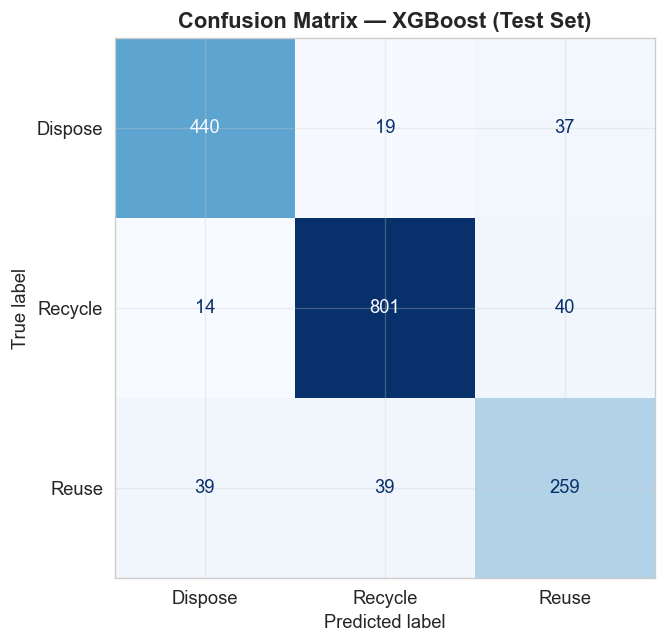

✅ Saved confusion_matrix.png


In [25]:
# Confusion matrix
cm = confusion_matrix(y_test, test_pred)
fig, ax = plt.subplots(figsize=(6, 5.5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f'Confusion Matrix — {best_model_name} (Test Set)', fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'confusion_matrix.png'), dpi=150)
plt.show()
print('✅ Saved confusion_matrix.png')

---
## 💾 Cell 9 — Save Results Summary

In [26]:
def to_serializable(v):
    if isinstance(v, (np.floating, np.float32, np.float64)):
        return float(v)
    if isinstance(v, (np.integer,)):
        return int(v)
    return v

summary = {
    'dataset_rows_raw':            len(df_raw),
    'dataset_rows_after_cleaning': len(df),
    'rows_dropped_missing':        len(df_raw) - len(df),
    'split': {'train': len(X_train), 'test': len(X_test), 'validation': len(X_val)},
    'results': {k: {kk: to_serializable(vv) for kk, vv in v.items()} for k, v in results.items()},
    'best_model':              best_model_name,
    'best_model_test_accuracy': float(test_acc),
}

out_path = os.path.join(RESULTS_DIR, 'results_summary.json')
with open(out_path, 'w') as f:
    json.dump(summary, f, indent=2, default=str)

print(f'✅ Saved results_summary.json → {os.path.abspath(out_path)}')
print('\nResults saved to ../results/ folder:')
for fname in os.listdir(RESULTS_DIR):
    fpath = os.path.join(RESULTS_DIR, fname)
    size_kb = os.path.getsize(fpath) / 1024
    print(f'  {fname:<45s}  {size_kb:.1f} KB')

✅ Saved results_summary.json → /Users/srinidhids/PROJECTS/MAJOR-PROJECT---52/results/results_summary.json

Results saved to ../results/ folder:
  confusion_matrix.png                           35.1 KB
  shap_single_part.png                           131.3 KB
  disposition_feature_importance.png             76.2 KB
  results_summary_v2.json                        299.3 KB
  risk_curve_mlp.png                             103.5 KB
  disposition_curve_mlp.png                      93.8 KB
  rf_training_curves.png                         90.5 KB
  xgboost_training_curves.png                    105.1 KB
  disposition_confusion_extrapolation.png        32.9 KB
  risk_curve_lstm.png                            87.1 KB
  risk_confusion_matrix.png                      40.1 KB
  disposition_model_comparison.png               88.5 KB
  disposition_training_curves.png                186.0 KB
  disposition_confusion_matrix.png               32.8 KB
  shap_global_importance.png                     119.

---
## ✅ Cell 10 — Pipeline Complete — Summary

| Step | Details |
|------|---------|
| Dataset | `automotive_material_lifecycle_v2.csv` (simulated, 9,000 rows) |
| Target | `Disposition` (Dispose / Recycle / Reuse); `Environmental Risk` excluded from features |
| Preprocessing | Drop NaN rows, Label Encode categoricals |
| Split | 70% Train / 20% Test / 10% Validation (stratified) |
| Models | Random Forest, XGBoost, SVM, Hybrid Stacking |
| Tuning | GridSearchCV (3-fold CV) for RF and XGBoost |
| Epoch tracking | XGBoost mlogloss + merror per boosting round |
| Output files | `results_summary.json`, `confusion_matrix.png`, `model_comparison.png`, `xgboost_training_curves.png`, `rf_feature_importance.png` |
| Output folder | `../results/` |